# Lab 9
## Name: Arnish Manwatkar
## Batch: C-C3
## Roll no: 38
## Lab: ML

In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score)

from scipy.cluster.hierarchy import linkage, dendrogram



In [4]:
df = pd.read_csv("Wholesale_customers_data.csv")

In [5]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


Algorithm

In [6]:
# Define features for clustering (excluding categorical columns Channel and Region)
X = df.drop(columns=['Channel', 'Region'])

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert to DataFrame for easier inspection
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
display(X_scaled_df.head())

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [7]:
print("Scaled Feature means (Approx Zero)")
print(X_scaled_df.mean().round(3))

Scaled Feature means (Approx Zero)
Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64


In [8]:
print("Scaled Feature means (Approx One)")
print(X_scaled_df.std(ddof=0).round(3))

Scaled Feature means (Approx One)
Fresh               1.0
Milk                1.0
Grocery             1.0
Frozen              1.0
Detergents_Paper    1.0
Delicassen          1.0
dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

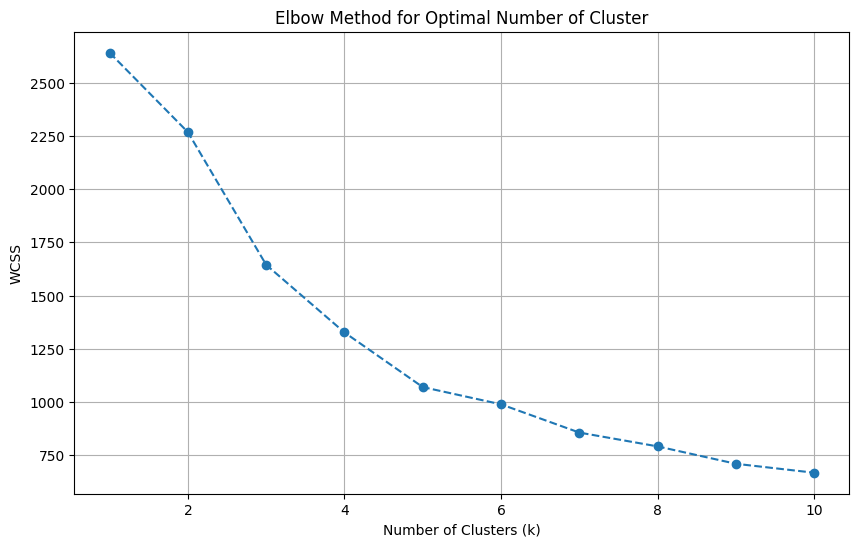

In [9]:
wcss = [] #Within the cluster among the square
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal Number of Cluster')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show

In [10]:
silhouette_values = []

for k in range(2,11):
  model = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = model.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, labels)
  silhouette_values.append(score)

silhouette_table = pd.DataFrame({'Number of Clusters': range(2, 11), 'Silhouette Score': silhouette_values})
display(silhouette_table.round(4))

,Number of Clusters,Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [11]:
suggested_k = int(
    silhouette_table.loc[silhouette_table['Silhouette Score'].idxmax(), 'Number of Clusters']
)
print("K Suggested by the higest Silhouette score: ", suggested_k)

K Suggested by the higest Silhouette score:  3


In [12]:
K = suggested_k

kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [13]:
df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("K-Means Clusturning Completed")
print("\n Number Of customers in each cluster:")
print(df_kmeans['KMeans_Cluster'].value_counts().sort_index())
print("\n Samples record with cluster labels")
display(df_kmeans.head())

K-Means Clusturning Completed

 Number Of customers in each cluster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

 Samples record with cluster labels


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [14]:
# Buils Hirearchical Clustering Model
hierarchical_model = AgglomerativeClustering(n_clusters=K,linkage="ward",metric="euclidean")

In [15]:
# Fit the hierarchical model and generate the labels
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

# Store the cluster Label
df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical clustering completed")
print("\n Number Of customers in each cluster:")
print(df_hierarchical['Hierarchical_Cluster'].value_counts().sort_index())
print("\n Samples record with cluster labels")
display(df_hierarchical.head())

Hierarchical clustering completed

 Number Of customers in each cluster:
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64

 Samples record with cluster labels


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


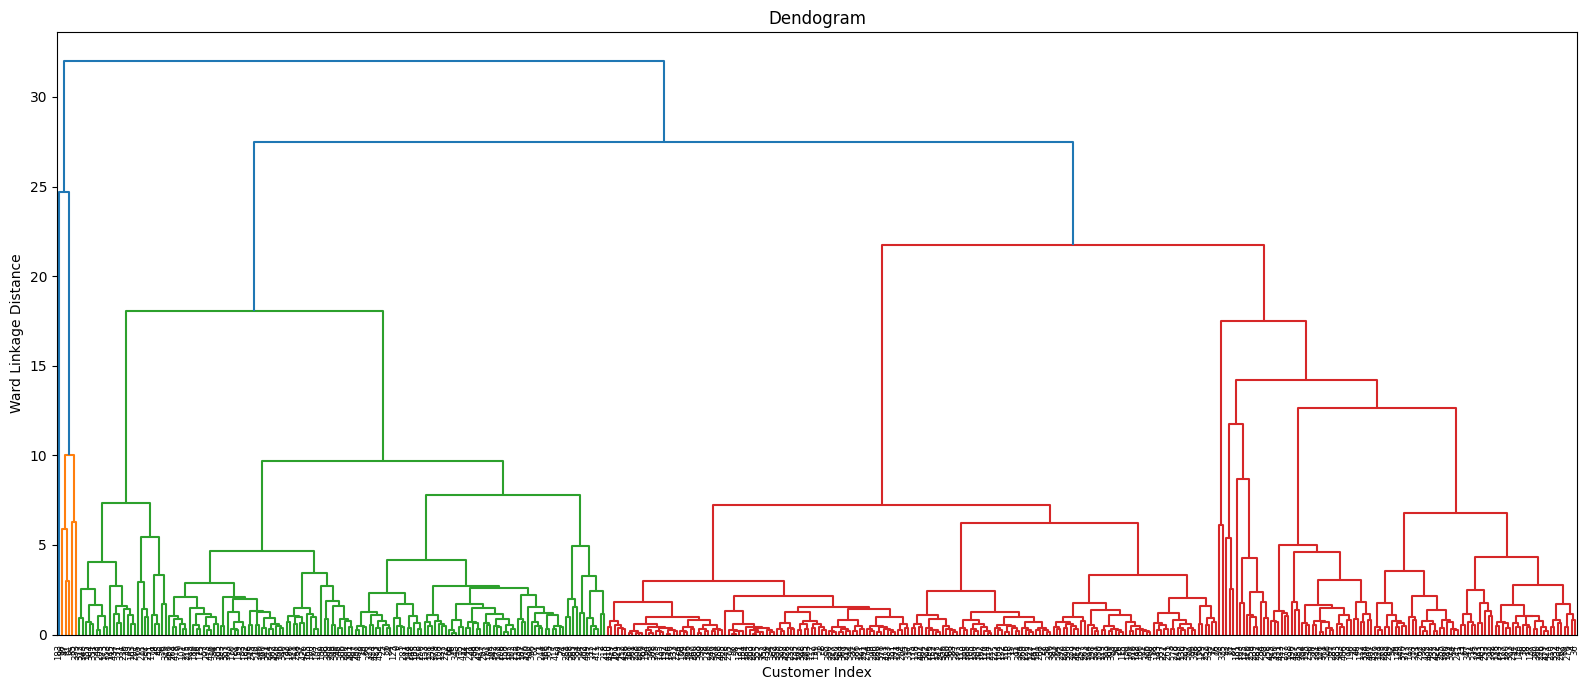

In [16]:
Z = linkage(X_scaled,method="ward",metric="euclidean")

plt.figure(figsize=(16,7))
dendrogram(Z,leaf_rotation=90,leaf_font_size=6)
plt.title("Dendogram")
plt.xlabel("Customer Index")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

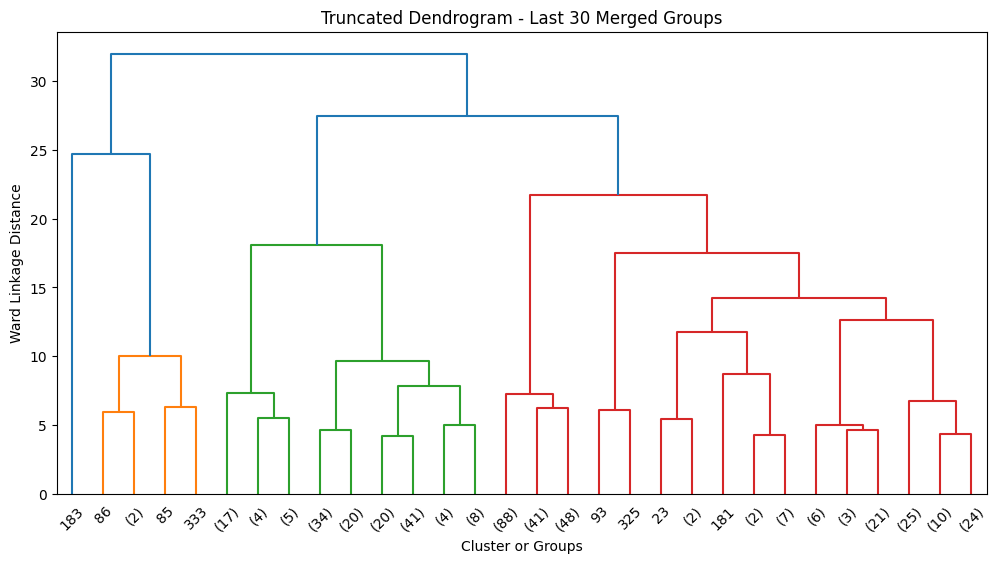

In [17]:
plt.figure(figsize=(12,6))
dendrogram(Z,truncate_mode="lastp",p=30,show_leaf_counts=True,leaf_rotation=45)

plt.title("Truncated Dendrogram - Last 30 Merged Groups")
plt.xlabel("Cluster or Groups")
plt.ylabel("Ward Linkage Distance")
plt.show

In [18]:
# Reduce six scaled features to two principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(
    "Variance explained by the two PC Components: ",
    round(pca.explained_variance_ratio_.sum()*100, 2),
    "%"
)

plot_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1],
                        "KMeans_Cluster": kmeans_labels.astype(str),
                        "Hierarchical_Cluster": hierarchical_labels.astype(str)
})

Variance explained by the two PC Components:  72.46 %


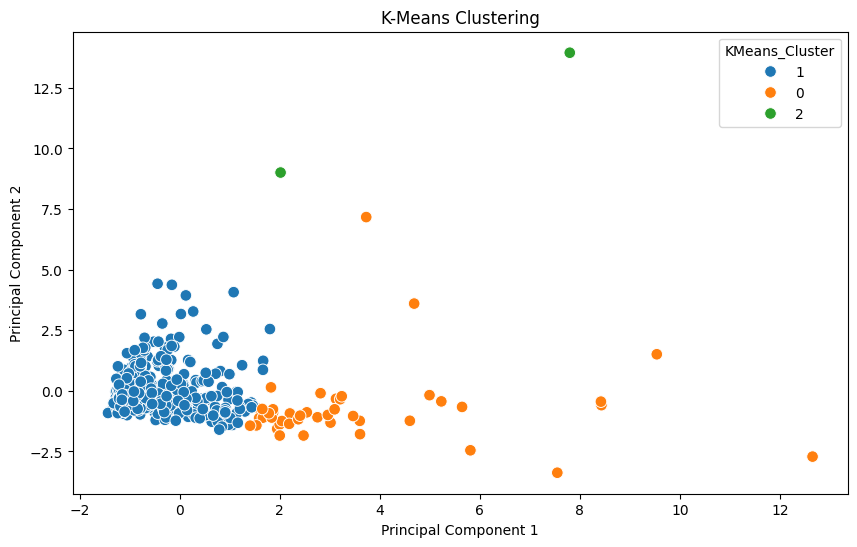

In [19]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="KMeans_Cluster", palette="tab10",s=70)
plt.title("K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [20]:
# Function to calculate clusturing evaluation metrics
def evaluate_clustering(X_data,labels,model_name):
  return{
      "Algorithm":model_name,
      "Number of Clusters":len(np.unique(labels)),
      "Silhouette Score":silhouette_score(X_data,labels)
  }

In [22]:
#Evaluate both models using the same scaled features
comparison = pd.DataFrame([evaluate_clustering(X_scaled, kmeans_labels, "")])
print(comparison)

  Algorithm  Number of Clusters  Silhouette Score
0                             3          0.548287
